# Chapitre 2 - Cours 3 : modèles statistiques, estimateurs restreints, biais-variance

Ce notebook couvre les sections 2.6 à 2.9 du livre :

1. le **modèle à erreur additive** $Y = f(X) + \varepsilon$ et l'apprentissage vu comme
   une **approximation de fonction** (moindres carrés, maximum de vraisemblance) ;
2. pourquoi il faut **restreindre** la classe des fonctions candidates ;
3. trois grandes familles d'estimateurs restreints : **pénalité de rugosité**,
   **noyaux**, **bases de fonctions** ;
4. le **compromis biais-variance** et le choix de la complexité.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## 1. Le modèle à erreur additive (section 2.6.1)

On suppose que les données sont engendrées par
$$Y = f(X) + \varepsilon \qquad \text{(éq. (2.29) du livre)},$$
où l'erreur aléatoire $\varepsilon$ vérifie $E(\varepsilon) = 0$ et est **indépendante**
de $X$. Alors $E(Y \mid X = x) = f(x) + E(\varepsilon) = f(x)$ : $f$ est exactement la
fonction de régression, et la loi conditionnelle de $Y$ sachant $X$ ne dépend de $X$
qu'à travers $f(X)$.

L'erreur $\varepsilon$ résume tout ce qui n'est pas mesuré : variables manquantes,
erreurs de mesure… C'est une approximation commode ; on peut l'assouplir (par exemple
avec une variance $\mathrm{Var}(Y\mid X = x) = \sigma^2(x)$ dépendant de $x$).

**Sortie qualitative.** Pour une classe $G$, on ne modélise pas une erreur additive,
mais directement les probabilités $p(x) = \Pr(G \mid X = x)$. Avec deux classes et le
codage $Y \in\{0,1\}$ : $E(Y \mid X = x) = p(x)$ et $\mathrm{Var}(Y\mid X = x) = p(x)(1 - p(x))$,
variance qui dépend de $x$ (loi de Bernoulli).

## 2. Apprendre, c'est approcher une fonction (section 2.6.3)

On dispose d'observations $(x_i, y_i)$ et l'on cherche une approximation $\hat f$ de $f$
dans une famille paramétrée $\{f_\theta\}$. Un exemple très général : les
**développements sur une base de fonctions**
$$f_\theta(x) = \sum_{k=1}^K h_k(x)\,\theta_k \qquad \text{(éq. (2.30))},$$
où les $h_k$ sont des transformations fixées de $x$ (puissances, sinus, cosinus…).
Le modèle est **linéaire en $\theta$**, même si $f_\theta$ n'est pas linéaire en $x$.

On estime $\theta$ en minimisant la somme des carrés résiduelle
$$\mathrm{RSS}(\theta) = \sum_{i=1}^N\big(y_i - f_\theta(x_i)\big)^2 \qquad \text{(éq. (2.32))},$$
qui se résout comme au cours 1 : il suffit de remplacer la matrice $\mathbf X$ par la
matrice $\mathbf H$ de terme général $H_{ik} = h_k(x_i)$.

Illustration : un polynôme de degré 5, $h_k(x) = t^{k-1}$ avec $t = 2x - 1$, ajusté à des données
sinusoïdales bruitées.

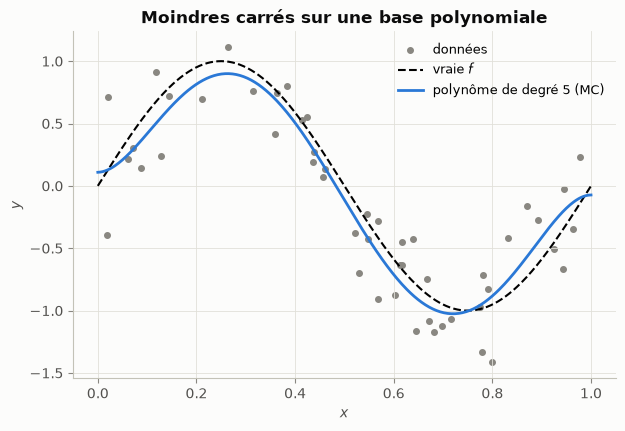

In [2]:
f_true = lambda x: np.sin(2 * np.pi * x)
N = 50
x = np.sort(rng.uniform(size=N))
y = f_true(x) + 0.3 * rng.normal(size=N)
x_plot = np.linspace(0, 1, 400)

# on utilise la variable recentrée t = 2x - 1 dans [-1, 1] : même famille de polynômes,
# mais matrice H mieux conditionnée numériquement
H = np.vander(2 * x - 1, 6, increasing=True)          # colonnes 1, t, ..., t^5
theta = c2.least_squares_fit(H, y, intercept=False)
fit_poly = np.vander(2 * x_plot - 1, 6, increasing=True) @ theta

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=16, color=GRAY, label="données")
ax.plot(x_plot, f_true(x_plot), color="k", lw=1.5, ls="--", label="vraie $f$")
ax.plot(x_plot, fit_poly, color=BLUE, label="polynôme de degré 5 (MC)")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Moindres carrés sur une base polynomiale")
ax.legend()
plt.show()

### Maximum de vraisemblance (éq. (2.33)-(2.36))

Un principe plus général que les moindres carrés est le **maximum de vraisemblance** :
si les $y_i$ sont indépendants de densité $\Pr_\theta(y)$, on maximise la
log-vraisemblance $L(\theta) = \sum_{i=1}^N \log\Pr_\theta(y_i)$ (éq. (2.33)), ce qui
revient à choisir le $\theta$ sous lequel les données observées sont les plus probables.

**Lien avec les moindres carrés.** Dans le modèle (2.29) avec $\varepsilon\sim\mathcal N(0,\sigma^2)$,
on a $\Pr(Y \mid X, \theta) = \mathcal N(f_\theta(X), \sigma^2)$ (éq. (2.34)). La densité
gaussienne vaut $\frac{1}{\sqrt{2\pi}\sigma}\exp\big(-\frac{(y - f_\theta(x))^2}{2\sigma^2}\big)$ ; en prenant le
logarithme et en sommant :
$$L(\theta) = -\frac N2\log(2\pi) - N\log\sigma - \frac{1}{2\sigma^2}\sum_{i=1}^N\big(y_i - f_\theta(x_i)\big)^2 \qquad \text{(éq. (2.35))}.$$
Seul le dernier terme dépend de $\theta$, avec un signe moins : maximiser $L$ revient à
**minimiser** $\mathrm{RSS}(\theta)$.

Vérifions-le numériquement : on maximise $L(\theta, \sigma)$ par un algorithme
d'optimisation générique et l'on compare aux moindres carrés.

In [3]:
from scipy.optimize import minimize


def neg_loglik(params):
    th, log_s = params[:-1], params[-1]
    s = np.exp(log_s)   # paramétrage par log(sigma) pour garantir sigma > 0
    r = y - H @ th
    return N / 2 * np.log(2 * np.pi) + N * log_s + (r @ r) / (2 * s ** 2)


opt = minimize(neg_loglik, np.zeros(7), method="BFGS", options={"gtol": 1e-8})
print("theta (max. vraisemblance):", np.round(opt.x[:-1], 3))
print("theta (moindres carrés)   :", np.round(theta, 3))
print("sigma_MV = %.4f ; sqrt(RSS/N) = %.4f" % (np.exp(opt.x[-1]),
      np.sqrt(np.sum((y - H @ theta) ** 2) / N)))

theta (max. vraisemblance): [-0.114 -3.29   0.274  6.339 -0.142 -3.14 ]
theta (moindres carrés)   : [-0.114 -3.29   0.274  6.339 -0.142 -3.14 ]
sigma_MV = 0.2607 ; sqrt(RSS/N) = 0.2607


> **Remarque.** Le maximum de vraisemblance de $\sigma$ est $\sqrt{\mathrm{RSS}/N}$
> (on annule la dérivée de (2.35) en $\sigma$). Pour une sortie qualitative à $K$ classes
> de probabilités $p_{k,\theta}(x)$, la log-vraisemblance est
> $L(\theta) = \sum_i \log p_{g_i,\theta}(x_i)$ (éq. (2.36)) : c'est l'**entropie croisée**,
> utilisée en régression logistique (chapitre 4).

## 3. Pourquoi faut-il restreindre la classe des fonctions ? (section 2.7)

Si l'on minimise $\mathrm{RSS}(f) = \sum_i(y_i - f(x_i))^2$ (éq. (2.37)) sur **toutes** les
fonctions $f$, il y a une infinité de solutions : toute fonction qui passe par les
points $(x_i, y_i)$ donne $\mathrm{RSS} = 0$. Ces solutions peuvent être de très mauvais
prédicteurs en dehors des $x_i$.

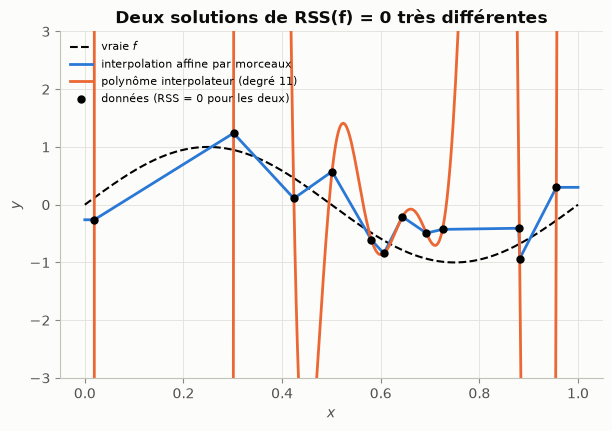

In [4]:
x_small = np.sort(rng.uniform(size=12))
y_small = f_true(x_small) + 0.3 * rng.normal(size=12)
interp_lin = np.interp(x_plot, x_small, y_small)
# interpolation polynomiale de Lagrange (degré 11) : passe aussi par tous les points
coef = np.polyfit(x_small, y_small, len(x_small) - 1)
interp_poly = np.polyval(coef, x_plot)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x_plot, f_true(x_plot), color="k", ls="--", lw=1.5, label="vraie $f$")
ax.plot(x_plot, interp_lin, color=BLUE, label="interpolation affine par morceaux")
ax.plot(x_plot, interp_poly, color=ORANGE, label="polynôme interpolateur (degré 11)")
ax.scatter(x_small, y_small, color="k", s=25, zorder=3, label="données (RSS = 0 pour les deux)")
ax.set_ylim(-3, 3)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Deux solutions de RSS(f) = 0 très différentes")
ax.legend(fontsize=8)
plt.show()

Pour obtenir une solution unique et raisonnable, il faut **restreindre** la classe des
fonctions, en imposant une forme de **régularité locale** : $f$ varie peu dans de petits
voisinages. La taille de ces voisinages règle la complexité. Toute méthode qui cherche
à varier finement dans **toutes** les directions d'un espace de grande dimension se
heurte cependant au fléau de la dimension (cours 2).

## 4. Trois familles d'estimateurs restreints (section 2.8)

### 4.1 Pénalité de rugosité (éq. (2.38)-(2.39))

On minimise un critère **pénalisé** $\mathrm{PRSS}(f; \lambda) = \mathrm{RSS}(f) + \lambda J(f)$,
où $J(f)$ est grand pour les fonctions trop irrégulières. L'exemple type est la
**spline de lissage** :
$$\mathrm{PRSS}(f;\lambda) = \sum_{i=1}^N\big(y_i - f(x_i)\big)^2 + \lambda\int\big[f''(x)\big]^2\,dx.$$
Pour $\lambda = 0$, toute fonction interpolante convient ; pour $\lambda = +\infty$,
seules les fonctions de dérivée seconde nulle (les droites) sont admises.

**Version discrète.** Sur une grille régulière, on approche $f''(x_i)$ par la différence
seconde $f_i - 2f_{i+1} + f_{i+2}$ (à un facteur près). En notant $D$ la matrice de ces
différences, on minimise $\|y - f\|^2 + \lambda\|Df\|^2$ sur $f \in \mathbb R^N$. Le gradient
$-2(y - f) + 2\lambda D^TDf$ s'annule pour
$$\hat f = (\mathbf I + \lambda D^TD)^{-1}y,$$
la matrice $\mathbf I + \lambda D^TD$ étant symétrique définie positive donc inversible.

In [ ]:
x_grid = np.linspace(0, 1, 100)
y_grid = f_true(x_grid) + 0.3 * rng.normal(size=100)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_grid, y_grid, s=10, color=GRAY, label="données")
for j, lam in enumerate([1, 100, 1e5]):
    ax.plot(x_grid, c2.penalized_smoother(y_grid, lam), color=COLORS[j],
            label="$\\lambda = %g$" % lam)
ax.set_xlabel("$x$")
ax.set_ylabel("$\\hat f(x)$")
ax.set_title("Lissage par pénalité de rugosité")
ax.legend()
plt.show()

### 4.2 Noyaux et régression locale (éq. (2.40)-(2.42))

On précise la forme du voisinage par un **noyau** $K_\lambda(x_0, x)$ qui donne un
poids aux points $x$ autour de $x_0$, par exemple le noyau gaussien
$$K_\lambda(x_0, x) = \frac1\lambda\exp\Big(-\frac{\|x - x_0\|^2}{2\lambda}\Big) \qquad \text{(éq. (2.40))},$$
dont les poids décroissent continûment avec la distance ($\lambda$ joue le rôle de la
variance et règle la largeur). L'estimateur le plus simple est la **moyenne pondérée de
Nadaraya-Watson** :
$$\hat f(x_0) = \frac{\sum_{i=1}^N K_\lambda(x_0, x_i)\,y_i}{\sum_{i=1}^N K_\lambda(x_0, x_i)} \qquad \text{(éq. (2.41))}.$$

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_grid, y_grid, s=10, color=GRAY, label="données")
for j, lam in enumerate([0.0002, 0.003, 0.05]):
    ax.plot(x_plot, c2.nadaraya_watson(x_grid, y_grid, x_plot, lam), color=COLORS[j],
            label="$\\lambda = %g$" % lam)
ax.set_xlabel("$x$")
ax.set_ylabel("$\\hat f(x)$")
ax.set_title("Estimateur à noyau gaussien de Nadaraya-Watson")
ax.legend()
plt.show()

Plus généralement, on peut ajuster localement un modèle $f_\theta$ en minimisant
$\sum_i K_\lambda(x_0, x_i)(y_i - f_\theta(x_i))^2$ (éq. (2.42)) : avec $f_\theta$ constant on
retrouve Nadaraya-Watson, avec $f_\theta$ affine la **régression linéaire locale**
(chapitre 6). Les $k$-ppv sont un cas particulier, avec un noyau à poids 0/1 dont la
largeur s'adapte à la densité des points.